# Лабораторная работа № 2. Консолидация разнородных источников: CSV + Excel + JSON → SQLite → аналитика

**Направление:** 38.04.05 «Бизнес-информатика», магистратура  
**Среда:** один ноутбук Google Colab, без Docker и без внешней СУБД · до 10 баллов за основную часть

## Цель

Собрать данные из трёх источников разного формата, провести аудит и очистку, загрузить результат в локальную реляционную базу SQLite, рассчитать выручку по субъектам и довести результат до управленческих выводов.

## Задачи

1. Прочитать три источника: справочник субъектов (CSV), события с объёмом (Excel) и цены по событиям (JSON).
2. Провести **аудит качества** по шести измерениям: полнота, уникальность, согласованность, валидность, целостность, точность.
3. Очистить данные с ведением **журнала изменений** и карантина: ни одна строка не исчезает молча.
4. Спроектировать схему в SQLite: первичные и внешние ключи, ограничения `CHECK`, индексы.
5. Показать и устранить эффект **fan-out при соединении один-ко-многим** — главную причину завышенной выручки в отчётности.
6. Сверить расчёт на SQL и в pandas, провести аналитику (концентрация, Парето и ABC, сезонность, структура по классам) и сформулировать выводы.
7. **Дополнительно, по желанию:** выгрузить витрину в BigQuery и повторить расчёт (необязательный раздел; основная работа полностью выполняется в SQLite).

## Чем эта работа отличается от версии с Docker и PostgreSQL

| | Прежняя схема | Текущая схема |
|---|---|---|
| Инфраструктура | Docker Compose, контейнер PostgreSQL, Jupyter в контейнере | один ноутбук в Colab |
| СУБД | PostgreSQL 15 на порту 5432 | SQLite: база — один файл рядом с ноутбуком |
| Запуск | установка Docker, `docker compose up`, проброс портов | «Выполнить все» |
| Что теряем | ничего существенного для учебной задачи | — |
| Что приобретаем | — | воспроизводимость, отсутствие проблем с портами и правами |

SQL остаётся тем же: `CREATE TABLE`, ключи, `JOIN`, `GROUP BY`, оконные конструкции и CTE. Отличия SQLite от PostgreSQL, важные для работы, разобраны в теоретическом блоке.

## Что сдаётся

Ноутбук **с выводами ячеек**, файл базы `*.sqlite` и выгрузка витрины, опубликованные в личном репозитории GitHub; в LMS сдаётся ссылка на репозиторий.

## Как выполнять работу

1. **Файл → Сохранить копию на Диске.**
2. В шаге 1 укажите номер варианта, выданный преподавателем. От него зависят предметная область, объём данных и набор дефектов.
3. Выполняйте ячейки сверху вниз: генерация источников → аудит → очистка → SQLite → аналитика → выводы.
4. Перед каждым шагом дано методическое обоснование, после — интерпретация результата. Места с пометкой `TODO` дописываете вы.
5. Раздел BigQuery необязателен. Он включается флагом `ENABLE_BIGQUERY` и требует аккаунта Google Cloud; без него работа выполняется полностью.
6. Перед сдачей запустите самопроверку: должно быть «Выполнено: 11 из 11».

**Важно про данные.** Источники генерируются кодом и намеренно содержат дефекты: дубликаты, пропуски, два формата даты, числа строками с валютой, отрицательные цены, записи с несуществующим внешним ключом. Это не ошибка генератора — это предмет работы. Задача аналитика не в том, чтобы получить красивое число, а в том, чтобы знать, из чего оно посчитано и что было отброшено.

## Теоретический блок

### 1. Консолидация: что это и где ломается

Консолидация — приведение данных из разных источников к единой модели, пригодной для анализа. Типовой конвейер:

```
Извлечение (Extract) → Профилирование → Очистка → Сопоставление ключей → Загрузка (Load) → Витрина → Анализ
```

Три формата, с которыми вы работаете, ведут себя по-разному:

| Формат | Что гарантирует | Типичные проблемы |
|---|---|---|
| **CSV** | ничего, кроме текста | кодировка, разделитель, отсутствие типов: `007` превращается в `7`, а `2025-03-17` — в дату не всегда |
| **Excel** | типы ячеек и автоформатирование | «умное» приведение типов, скрытые пробелы, даты как числа, разные листы и объединённые ячейки |
| **JSON** | структуру и типы | вложенность, разный набор полей у записей, числа строками |

Общее правило: **читать всё как текст и приводить типы явно**. В работе так и сделано — `dtype=str` при чтении, затем контролируемое преобразование.

### 2. Шесть измерений качества данных

| Измерение | Вопрос | Как проверяется в работе |
|---|---|---|
| Полнота | всё ли на месте | доля непустых значений по каждой колонке |
| Уникальность | нет ли дублей | дубликаты строк и повторы ключей |
| Согласованность | одинаково ли записано | два формата даты, числа с валютой и пробелами |
| Валидность | попадает ли в допустимый диапазон | отрицательные цены, нулевой объём |
| Целостность | сходятся ли ссылки между таблицами | события с `entity_id`, которого нет в справочнике |
| Точность | похоже ли на правду | выбросы по правилу 3×IQR |

Принципиальное правило работы: **пропуск не равен нулю**. Замена `NaN` на 0 занижает средние и портит медианы; строка с непригодным значением отправляется в карантин, а не удаляется молча.

### 3. Ключи, кардинальность и fan-out — центральная идея работы

У связи между таблицами есть кардинальность:

* **1 : 1** — одной записи соответствует одна;
* **1 : N** — у события несколько ценовых строк (разные классы);
* **N : M** — требует таблицы-связки.

Если соединить три таблицы «в лоб», строка события повторится столько раз, сколько у него ценовых строк. Это и есть **fan-out**: сумма объёма и выручки завышается кратно.

```
events (1 строка, 180 единиц)      prices (3 строки: 5 000, 12 000, 25 000)
        └──────────── JOIN ────────────┘
результат: 3 строки по 180 единиц → SUM(volume) = 540 вместо 180
```

Правильный порядок действий: **сначала свернуть подчинённую таблицу до уровня родителя (агрегировать цены по событию), потом соединять**. В работе оба варианта считаются и сравниваются численно — вы увидите коэффициент завышения на своих данных.

Формула расчёта после свёртки:

$$
Revenue_{entity} = \sum_{e \in events(entity)} volume_e \cdot \overline{price}_e,
\qquad
\overline{price}_e = \frac{1}{n_e}\sum_{i=1}^{n_e} price_{e,i}
$$

Среднее здесь — упрощение. Если известно количество проданных единиц по каждому классу, корректнее взвешенное среднее; это вынесено в задание со звёздочкой.

### 4. SQLite: что важно знать

SQLite — встраиваемая СУБД: вся база это один файл, сервер не нужен. Именно поэтому она заменяет здесь PostgreSQL в контейнере.

| Особенность | Следствие для работы |
|---|---|
| Внешние ключи **выключены** по умолчанию | обязательно `PRAGMA foreign_keys = ON;` в начале сессии |
| Динамическая типизация (type affinity) | в колонку `INTEGER` можно записать текст: типы контролирует ваш код и `CHECK` |
| Нет отдельного типа `DATE` | даты хранятся строками `YYYY-MM-DD` — формат, который корректно сортируется |
| Нет `TRUE/FALSE` | используйте 0 и 1 |
| Одна запись за раз, читателей много | для учебной задачи и витрин на миллионы строк этого достаточно |
| Поддерживает CTE и оконные функции | `WITH ... AS`, `ROW_NUMBER() OVER (...)` работают как в PostgreSQL |

Чего в SQLite нет по сравнению с PostgreSQL: серверного доступа по сети, ролей и прав, материализованных представлений, параллельной записи, богатых типов (`JSONB`, `ARRAY`, геоданные). Когда эти возможности понадобятся, переносится тот же SQL — меняется строка подключения.

### 5. Три уровня хранения: когда что выбирать

| | SQLite | PostgreSQL | BigQuery |
|---|---|---|---|
| Развёртывание | файл, ноль настройки | сервер или контейнер | облачный сервис |
| Объём | до сотен миллионов строк на одной машине | терабайты | петабайты |
| Модель оплаты | бесплатно | инфраструктура | за объём прочитанных данных |
| Параллельная запись | одна | много | пакетная загрузка |
| Где уместна | прототип, учебная работа, витрина одного аналитика | продуктовая база, многопользовательский доступ | аналитика на больших объёмах, редкие тяжёлые запросы |

Учебная витрина этой работы — десятки тысяч строк. Для неё SQLite избыточно достаточен, и это тоже профессиональный вывод: инструмент выбирается под объём и режим доступа, а не по громкости названия.

### Шаг 1. Окружение и параметры варианта

**Методическое обоснование.** Colab — одноразовая среда: нужные библиотеки проверяются и при необходимости доустанавливаются, рабочая папка создаётся заново. Номер варианта задаёт предметную область, объём генерации и уровень дефектов — от него детерминированно зависят все дальнейшие числа, поэтому результат воспроизводим.

In [1]:
#@title Шаг 1. Окружение и параметры варианта { display-mode: "form" }
VARIANT = 27                 #@param {type:"slider", min:1, max:30, step:1}
ENABLE_BIGQUERY = False      #@param {type:"boolean"}
RANDOM_CHECK = True          #@param {type:"boolean"}

import importlib, json, math, os, re, sqlite3, subprocess, sys, textwrap, warnings
from datetime import datetime, timedelta
from pathlib import Path

def ensure(pkg, module=None):
    try:
        importlib.import_module(module or pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
        importlib.invalidate_caches()

for pkg, mod in [("pandas", "pandas"), ("numpy", "numpy"), ("openpyxl", "openpyxl"),
                 ("matplotlib", "matplotlib"), ("seaborn", "seaborn")]:
    ensure(pkg, mod)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 11})
pd.set_option("display.width", 170, "display.max_columns", 50, "display.float_format", "{:,.2f}".format)

WORK = Path("/content/pw2" if Path("/content").exists() else "pw2_work")
DATA = WORK / "data"
DATA.mkdir(parents=True, exist_ok=True)
DB_PATH = WORK / f"consolidation_variant_{VARIANT}.sqlite"

def todo(step):
    raise NotImplementedError(f"Не выполнен шаг TODO {step} — допишите код в отмеченном месте")

def nf(x, digits=0):
    """Число с пробелом-разделителем разрядов: 1 234 567."""
    if x is None or (isinstance(x, float) and math.isnan(x)):
        return "—"
    return f"{x:,.{digits}f}".replace(",", " ")

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"sqlite3 {sqlite3.sqlite_version}")
print(f"Рабочая папка: {WORK}")

Python 3.13.18 | pandas 2.2.3 | numpy 2.1.3 | sqlite3 3.45.1
Рабочая папка: /content/pw2


In [2]:
#@title Шаг 1.1. Конфигурация варианта { display-mode: "form" }
VARIANTS = [
{
"id": 1,
"domain": "Авиаперевозки",
"parent": "Авиакомпании",
"event": "Рейсы",
"price": "Билеты",
"unit": "пассажиров",
"cls": "класс билета",
"analytics": "Сезонность перевозок: в каком месяце выручка максимальна и какие компании её формируют",
"seed": 1007,
"n_parents": 9,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Авиакомпании — CSV, Рейсы — XLSX, Билеты — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Авиакомпании»"
},
{
"id": 2,
"domain": "Розничная сеть",
"parent": "Магазины",
"event": "Чеки",
"price": "Позиции чека",
"unit": "единиц товара",
"cls": "категория товара",
"analytics": "ABC-анализ магазинов: какие точки дают 80 % выручки",
"seed": 1014,
"n_parents": 10,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Магазины — CSV, Чеки — XLSX, Позиции чека — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Магазины»"
},
{
"id": 3,
"domain": "Логистика",
"parent": "Перевозчики",
"event": "Отгрузки",
"price": "Тарифы",
"unit": "паллет",
"cls": "тип тарифа",
"analytics": "Загрузка перевозчиков: связь объёма и средней ставки",
"seed": 1021,
"n_parents": 11,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Перевозчики — CSV, Отгрузки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Перевозчики»"
},
{
"id": 4,
"domain": "Телеком",
"parent": "Операторы",
"event": "Сессии связи",
"price": "Тарификация",
"unit": "минут",
"cls": "тарифный план",
"analytics": "Доля тарифных планов в выручке и средний чек сессии",
"seed": 1028,
"n_parents": 12,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Операторы — CSV, Сессии связи — XLSX, Тарификация — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы»"
},
{
"id": 5,
"domain": "Банковский ритейл",
"parent": "Отделения",
"event": "Операции",
"price": "Комиссии",
"unit": "транзакций",
"cls": "тип комиссии",
"analytics": "Эффективность отделений: выручка на одну операцию",
"seed": 1035,
"n_parents": 8,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Отделения — CSV, Операции — XLSX, Комиссии — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Отделения»"
},
{
"id": 6,
"domain": "Гостиничный бизнес",
"parent": "Отели",
"event": "Бронирования",
"price": "Тарифы номеров",
"unit": "ночей",
"cls": "категория номера",
"analytics": "Сезонность загрузки и вклад категорий номеров",
"seed": 1042,
"n_parents": 9,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Отели — CSV, Бронирования — XLSX, Тарифы номеров — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Отели»"
},
{
"id": 7,
"domain": "Образовательные услуги",
"parent": "Центры",
"event": "Группы",
"price": "Стоимость обучения",
"unit": "слушателей",
"cls": "формат обучения",
"analytics": "Выручка на слушателя и сравнение форматов",
"seed": 1049,
"n_parents": 10,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Центры — CSV, Группы — XLSX, Стоимость обучения — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Центры»"
},
{
"id": 8,
"domain": "Медицинские клиники",
"parent": "Клиники",
"event": "Приёмы",
"price": "Прейскурант",
"unit": "пациентов",
"cls": "вид услуги",
"analytics": "Структура выручки по видам услуг и загрузка клиник",
"seed": 1056,
"n_parents": 11,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Клиники — CSV, Приёмы — XLSX, Прейскурант — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Клиники»"
},
{
"id": 9,
"domain": "Энергосбыт",
"parent": "Сбытовые компании",
"event": "Поставки",
"price": "Тарифы",
"unit": "МВт·ч",
"cls": "категория потребителя",
"analytics": "Концентрация выручки по категориям потребителей",
"seed": 1063,
"n_parents": 12,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Сбытовые компании — CSV, Поставки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сбытовые компании»"
},
{
"id": 10,
"domain": "Маркетплейс",
"parent": "Продавцы",
"event": "Заказы",
"price": "Цены товаров",
"unit": "единиц",
"cls": "категория товара",
"analytics": "Топ продавцов и доля категорий в обороте",
"seed": 1070,
"n_parents": 8,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Продавцы — CSV, Заказы — XLSX, Цены товаров — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Продавцы»"
},
{
"id": 11,
"domain": "Общественный транспорт",
"parent": "Перевозчики",
"event": "Маршруты-рейсы",
"price": "Тарифы проезда",
"unit": "пассажиров",
"cls": "тип билета",
"analytics": "Выручка по типам билетов и пиковые месяцы",
"seed": 1077,
"n_parents": 9,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Перевозчики — CSV, Маршруты-рейсы — XLSX, Тарифы проезда — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Перевозчики»"
},
{
"id": 12,
"domain": "Страхование",
"parent": "Агентства",
"event": "Договоры",
"price": "Тарифные ставки",
"unit": "объектов",
"cls": "вид страхования",
"analytics": "Средняя премия по видам страхования и вклад агентств",
"seed": 1084,
"n_parents": 10,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Агентства — CSV, Договоры — XLSX, Тарифные ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Агентства»"
},
{
"id": 13,
"domain": "Грузовые ж/д перевозки",
"parent": "Операторы вагонов",
"event": "Отправки",
"price": "Ставки",
"unit": "тонн",
"cls": "род груза",
"analytics": "Доходность по родам груза и сезонность отправок",
"seed": 1091,
"n_parents": 11,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Операторы вагонов — CSV, Отправки — XLSX, Ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы вагонов»"
},
{
"id": 14,
"domain": "Общепит",
"parent": "Рестораны",
"event": "Заказы",
"price": "Цены блюд",
"unit": "порций",
"cls": "категория меню",
"analytics": "Средний чек и вклад категорий меню",
"seed": 1098,
"n_parents": 12,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Рестораны — CSV, Заказы — XLSX, Цены блюд — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Рестораны»"
},
{
"id": 15,
"domain": "Фитнес-сети",
"parent": "Клубы",
"event": "Визиты и покупки",
"price": "Прайс услуг",
"unit": "услуг",
"cls": "тип абонемента",
"analytics": "Выручка на клуб и структура абонементов",
"seed": 1105,
"n_parents": 8,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Клубы — CSV, Визиты и покупки — XLSX, Прайс услуг — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Клубы»"
},
{
"id": 16,
"domain": "Аренда спецтехники",
"parent": "Парки техники",
"event": "Смены аренды",
"price": "Ставки аренды",
"unit": "машино-часов",
"cls": "тип техники",
"analytics": "Утилизация парка и доходность типов техники",
"seed": 1112,
"n_parents": 9,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Парки техники — CSV, Смены аренды — XLSX, Ставки аренды — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Парки техники»"
},
{
"id": 17,
"domain": "Курьерская доставка",
"parent": "Службы доставки",
"event": "Доставки",
"price": "Тарифы",
"unit": "посылок",
"cls": "скорость доставки",
"analytics": "Доля экспресс-доставки в выручке",
"seed": 1119,
"n_parents": 10,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Службы доставки — CSV, Доставки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Службы доставки»"
},
{
"id": 18,
"domain": "Оптовая торговля",
"parent": "Дистрибьюторы",
"event": "Поставки",
"price": "Прайс-листы",
"unit": "коробов",
"cls": "товарная группа",
"analytics": "Парето по товарным группам и вклад дистрибьюторов",
"seed": 1126,
"n_parents": 11,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Дистрибьюторы — CSV, Поставки — XLSX, Прайс-листы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Дистрибьюторы»"
},
{
"id": 19,
"domain": "Автосервис",
"parent": "Сервисные центры",
"event": "Заказ-наряды",
"price": "Прейскурант работ",
"unit": "нормо-часов",
"cls": "вид работ",
"analytics": "Выручка по видам работ и загрузка центров",
"seed": 1133,
"n_parents": 12,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Сервисные центры — CSV, Заказ-наряды — XLSX, Прейскурант работ — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сервисные центры»"
},
{
"id": 20,
"domain": "Цифровые подписки",
"parent": "Сервисы",
"event": "Подписки",
"price": "Тарифные планы",
"unit": "подписчиков",
"cls": "план подписки",
"analytics": "Структура подписной базы и выручка на подписчика",
"seed": 1140,
"n_parents": 8,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Сервисы — CSV, Подписки — XLSX, Тарифные планы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сервисы»"
},
{
"id": 21,
"domain": "Сельхозпроизводство",
"parent": "Хозяйства",
"event": "Партии отгрузки",
"price": "Закупочные цены",
"unit": "тонн",
"cls": "культура",
"analytics": "Доходность культур и сезонность отгрузок",
"seed": 1147,
"n_parents": 9,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Хозяйства — CSV, Партии отгрузки — XLSX, Закупочные цены — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Хозяйства»"
},
{
"id": 22,
"domain": "Строительный ритейл",
"parent": "Гипермаркеты",
"event": "Продажи",
"price": "Цены материалов",
"unit": "единиц",
"cls": "группа материалов",
"analytics": "Сезонность продаж и вклад групп материалов",
"seed": 1154,
"n_parents": 10,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Гипермаркеты — CSV, Продажи — XLSX, Цены материалов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Гипермаркеты»"
},
{
"id": 23,
"domain": "Морские перевозки",
"parent": "Судоходные линии",
"event": "Рейсы судов",
"price": "Фрахтовые ставки",
"unit": "TEU",
"cls": "тип контейнера",
"analytics": "Доходность линий и структура по типам контейнеров",
"seed": 1161,
"n_parents": 11,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Судоходные линии — CSV, Рейсы судов — XLSX, Фрахтовые ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Судоходные линии»"
},
{
"id": 24,
"domain": "Аптечные сети",
"parent": "Аптеки",
"event": "Продажи",
"price": "Цены препаратов",
"unit": "упаковок",
"cls": "группа препаратов",
"analytics": "Вклад товарных групп и сравнение точек",
"seed": 1168,
"n_parents": 12,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Аптеки — CSV, Продажи — XLSX, Цены препаратов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Аптеки»"
},
{
"id": 25,
"domain": "Кинотеатры",
"parent": "Кинотеатры",
"event": "Сеансы",
"price": "Цены билетов",
"unit": "зрителей",
"cls": "тип сеанса",
"analytics": "Заполняемость залов и выручка по типам сеансов",
"seed": 1175,
"n_parents": 8,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Кинотеатры — CSV, Сеансы — XLSX, Цены билетов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Кинотеатры»"
},
{
"id": 26,
"domain": "Промышленное производство",
"parent": "Заводы",
"event": "Партии продукции",
"price": "Отпускные цены",
"unit": "тонн",
"cls": "марка продукции",
"analytics": "Вклад марок продукции и сезонность отгрузок",
"seed": 1182,
"n_parents": 9,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Заводы — CSV, Партии продукции — XLSX, Отпускные цены — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Заводы»"
},
{
"id": 27,
"domain": "Рекламные площадки",
"parent": "Площадки",
"event": "Кампании",
"price": "Ставки размещения",
"unit": "показов (тыс.)",
"cls": "формат размещения",
"analytics": "Доходность форматов и концентрация выручки",
"seed": 1189,
"n_parents": 10,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Площадки — CSV, Кампании — XLSX, Ставки размещения — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Площадки»"
},
{
"id": 28,
"domain": "ЖКХ",
"parent": "Управляющие компании",
"event": "Начисления",
"price": "Тарифы услуг",
"unit": "объектов",
"cls": "вид услуги",
"analytics": "Структура начислений и сравнение управляющих компаний",
"seed": 1196,
"n_parents": 11,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Управляющие компании — CSV, Начисления — XLSX, Тарифы услуг — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Управляющие компании»"
},
{
"id": 29,
"domain": "Каршеринг",
"parent": "Операторы",
"event": "Поездки",
"price": "Тарифы поездок",
"unit": "минут",
"cls": "класс автомобиля",
"analytics": "Выручка на поездку и вклад классов автомобилей",
"seed": 1203,
"n_parents": 12,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Операторы — CSV, Поездки — XLSX, Тарифы поездок — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы»"
},
{
"id": 30,
"domain": "Авиаперевозки (эталон преподавателя)",
"parent": "Авиакомпании",
"event": "Рейсы",
"price": "Билеты",
"unit": "пассажиров",
"cls": "класс билета",
"analytics": "Полный разбор: качество данных, fan-out при JOIN, сезонность, концентрация выручки",
"seed": 1210,
"n_parents": 8,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Авиакомпании — CSV, Рейсы — XLSX, Билеты — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Авиакомпании»"
}
]

def variant_config(v=None):
    v = VARIANT if v is None else int(v)
    found = [x for x in VARIANTS if x["id"] == v]
    if not found:
        raise ValueError("Номер варианта должен быть от 1 до 30")
    return found[0]

CFG = variant_config()
print(f"Вариант {CFG['id']} — {CFG['domain']}")
print(textwrap.fill(CFG["task"], 104))
print(f"\nCSV  : {CFG['parent']}        (справочник субъектов)")
print(f"XLSX : {CFG['event']}          (события, объём в единицах: {CFG['unit']})")
print(f"JSON : {CFG['price']}          (цены, разрез: {CFG['cls']})")
print(f"\nОбъём генерации: субъектов {CFG['n_parents']}, событий {nf(CFG['n_events'])}, "
      f"уровень дефектов {'★' * CFG['defect_level']}")
print(textwrap.fill("Аналитическая задача: " + CFG["analytics"], 104))

Вариант 27 — Рекламные площадки
Консолидировать три источника (Площадки — CSV, Кампании — XLSX, Ставки размещения — JSON), провести
аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Площадки»

CSV  : Площадки        (справочник субъектов)
XLSX : Кампании          (события, объём в единицах: показов (тыс.))
JSON : Ставки размещения          (цены, разрез: формат размещения)

Объём генерации: субъектов 10, событий 4 500, уровень дефектов ★
Аналитическая задача: Доходность форматов и концентрация выручки


**Интерпретация.** Убедитесь, что версия pandas и SQLite вывелись, а рабочая папка создана. Номер варианта определяет всё дальнейшее: если вы его измените, перезапустите ноутбук целиком, иначе данные и выводы будут из разных вариантов.

### Шаг 2. Генерация трёх источников

**Методическое обоснование.** В реальном проекте источники приходят от разных владельцев: бухгалтерия присылает Excel, ИТ-система выгружает JSON, справочник ведётся в CSV. Мы воспроизводим эту ситуацию, включая типичные дефекты: расхождение форматов дат, числа с валютой в текстовом поле, дубликаты, битые внешние ключи. Дефекты внесены осознанно и детерминированно — при проверке преподаватель знает, что именно вы должны были найти.

In [3]:
#@title Шаг 2. Генерация трёх источников: CSV, XLSX, JSON { display-mode: "form" }
# Данные генерируются детерминированно от номера варианта: у каждого студента свои числа,
# но одинаковая структура. В данные намеренно внесены дефекты — их предстоит найти на шаге 3.
def generate_sources(cfg, out_dir=DATA):
    rng = np.random.default_rng(cfg["seed"])
    lvl = cfg["defect_level"]

    # ---------- 1. Справочник субъектов (CSV) --------------------------------------
    regions = ["Москва", "Санкт-Петербург", "Новосибирск", "Екатеринбург", "Казань",
               "Краснодар", "Самара", "Пермь", "Ростов-на-Дону", "Уфа", "Тюмень", "Омск"]
    n = cfg["n_parents"]
    cities = list(rng.choice(regions, n, replace=False))
    parents = pd.DataFrame({
        "entity_id": [f"E{i:03d}" for i in range(1, n + 1)],
        "entity_name": [f"{cfg['parent']} «{city}»" for city in cities],
        "region": cities,                      # регион совпадает с городом в названии
        "founded_year": rng.integers(1990, 2021, n),
    })
    # дефекты справочника: дубль строки, «грязное» имя, пропуск в регионе
    parents.loc[len(parents)] = parents.iloc[1].tolist()                       # полный дубликат
    parents.loc[2, "entity_name"] = "  " + parents.loc[2, "entity_name"].upper() + " "
    if lvl >= 2:
        parents.loc[3, "region"] = None
    parents.to_csv(out_dir / "entities.csv", index=False, encoding="utf-8")

    # ---------- 2. События с объёмом (XLSX) ----------------------------------------
    m = cfg["n_events"]
    start = datetime(2025, 1, 1)
    event_ids = [f"EV{i:06d}" for i in range(1, m + 1)]
    entity_ids = rng.choice(parents["entity_id"].iloc[:n].to_numpy(), m,
                            p=np.linspace(2.2, 0.6, n) / np.linspace(2.2, 0.6, n).sum())
    day_offsets = rng.integers(0, 365, m)
    # сезонность: летние и декабрьские месяцы нагружены сильнее
    season_boost = rng.random(m)
    dates = [start + timedelta(days=int(d)) for d in day_offsets]
    base_volume = rng.integers(60, 320, m)
    volume = np.where([d.month in (6, 7, 8, 12) for d in dates],
                      (base_volume * (1.15 + 0.25 * season_boost)).astype(int), base_volume)
    events = pd.DataFrame({
        "event_id": event_ids,
        "entity_id": entity_ids,
        "event_date": [d.strftime("%Y-%m-%d") for d in dates],
        "route": [f"{a} — {b}" for a, b in zip(rng.choice(regions, m), rng.choice(regions, m))],
        "volume_units": volume,
        "asset_type": rng.choice(["Тип A", "Тип B", "Тип C", "Тип D"], m),
    })
    # дефекты событий
    idx = rng.choice(m, size=max(6, m // 100), replace=False)
    k = len(idx) // 3
    part_date, part_null, part_text = idx[:k], idx[k:2 * k], idx[2 * k:]
    events.loc[part_date, "event_date"] = [                                   # другой формат даты
        datetime.strptime(d, "%Y-%m-%d").strftime("%d.%m.%Y")
        for d in events.loc[part_date, "event_date"]]
    events["volume_units"] = events["volume_units"].astype("object")
    events.loc[part_null, "volume_units"] = None                              # пропуски объёма
    events.loc[part_text, "volume_units"] = [                                 # число строкой с пробелом
        f"{int(v)} " for v in rng.integers(80, 200, len(part_text))]
    if lvl >= 2:                                                               # строки-сироты по FK
        orphan_idx = rng.choice(m, size=max(3, m // 200), replace=False)
        events.loc[orphan_idx, "entity_id"] = "E999"
    if lvl >= 3:                                                               # дубли событий
        events = pd.concat([events, events.sample(max(5, m // 150), random_state=cfg["seed"])],
                           ignore_index=True)
    events.to_excel(out_dir / "events.xlsx", index=False)

    # ---------- 3. Цены по событиям (JSON) -----------------------------------------
    classes = [f"{cfg['cls']} 1", f"{cfg['cls']} 2", f"{cfg['cls']} 3"]
    rows = []
    counter = 1
    for eid in event_ids:
        for _ in range(int(rng.integers(1, 4))):        # 1–3 строки цен на событие → fan-out
            klass = str(rng.choice(classes))
            mult = {classes[0]: 1.0, classes[1]: 2.6, classes[2]: 5.2}[klass]
            price = round(float(rng.uniform(2500, 9000)) * mult, 2)
            rows.append({"price_id": f"PR{counter:07d}", "event_id": eid,
                         "unit_price": price, "price_class": klass})
            counter += 1
    prices = pd.DataFrame(rows)
    # дефекты цен
    bad = rng.choice(len(prices), size=max(6, len(prices) // 150), replace=False)
    kb = len(bad) // 3
    bad_text, bad_null, bad_neg = bad[:kb], bad[kb:2 * kb], bad[2 * kb:]
    prices["unit_price"] = prices["unit_price"].astype("object")
    prices.loc[bad_text, "unit_price"] = [                                      # цена строкой с валютой
        f"{v:,.2f} ₽".replace(",", " ") for v in rng.uniform(3000, 9000, len(bad_text))]
    prices.loc[bad_null, "unit_price"] = None                                   # пропуски
    if lvl >= 2:
        prices.loc[bad_neg, "unit_price"] = -1 * rng.uniform(1000, 5000, len(bad_neg))
    if lvl >= 3:                                                                 # дубли строк цен
        prices = pd.concat([prices, prices.sample(max(5, len(prices) // 200), random_state=cfg["seed"])],
                           ignore_index=True)
    (out_dir / "prices.json").write_text(
        json.dumps(prices.to_dict("records"), ensure_ascii=False, indent=1, default=str),
        encoding="utf-8")

    return {"entities.csv": len(parents), "events.xlsx": len(events), "prices.json": len(prices)}

created = generate_sources(CFG)
for name, rows in created.items():
    size_kb = (DATA / name).stat().st_size / 1024
    print(f"{name:<15} строк: {nf(rows):>8}   размер: {size_kb:8.1f} КБ")
print("\nФайлы лежат в:", DATA)

entities.csv    строк:       11   размер:      0.8 КБ
events.xlsx     строк:    4 500   размер:    165.7 КБ
prices.json     строк:    8 988   размер:   1233.2 КБ

Файлы лежат в: /content/pw2/data


**Интерпретация.** Три файла созданы в трёх разных форматах и заметно различаются по размеру: JSON тяжелее CSV при том же смысле, потому что повторяет имена полей в каждой записи. Число строк цен больше числа событий — это и есть связь один-ко-многим, которая позже даст fan-out.

### Шаг 3. Загрузка и аудит качества

**Методическое обоснование.** Аудит до очистки — обязательный этап: он фиксирует исходное состояние данных и даёт основание для решений. Всё читается как текст (`dtype=str`), чтобы pandas не «помог» с типами и не скрыл проблему. Профиль источников показывает структуру, журнал качества — конкретные дефекты с числом затронутых строк, расчёт кардинальности — риск fan-out до того, как он испортит выручку.

In [4]:
#@title Шаг 3. Загрузка источников и аудит качества (задание) { display-mode: "form" }
raw_entities = pd.read_csv(DATA / "entities.csv", dtype=str)
raw_events = pd.read_excel(DATA / "events.xlsx", dtype=str)
raw_prices = pd.DataFrame(json.loads((DATA / "prices.json").read_text(encoding="utf-8")))

SOURCES = {"CSV · " + CFG["parent"]: raw_entities,
           "XLSX · " + CFG["event"]: raw_events,
           "JSON · " + CFG["price"]: raw_prices}

# ------------------------------------------------------------------ TODO 3.1
def profile_table(df, name):
    """Постройте профиль источника: по каждой колонке — тип, доля заполненности,
    число уникальных значений и два примера значений. Верните DataFrame."""
    rows = []
    for column in df.columns:
        values = df[column]
        filled = values.notna() & values.astype('string').str.strip().ne('').fillna(False)
        examples = values[filled].astype(str).head(2).tolist()
        rows.append({
            'источник': name,
            'колонка': column,
            'тип': str(values.dtype),
            'заполнено, %': round(filled.mean() * 100, 1),
            'уникальных': values[filled].nunique(),
            'примеры': ' | '.join(examples),
        })
    return pd.DataFrame(rows)

profiles = pd.concat([profile_table(df, name) for name, df in SOURCES.items()], ignore_index=True)
display(profiles)

# ------------------------------------------------------------------ TODO 3.2
# Заполните журнал проблем качества по шести измерениям. Для каждой найденной проблемы —
# строка с полями: измерение, источник, проблема, число строк, решение.
#   Полнота        — пропуски по колонкам
#   Уникальность   — полные дубликаты и повторы ключей (entity_id, event_id, price_id)
#   Согласованность— два формата даты, числа строками с валютой и пробелами
#   Валидность     — отрицательные цены, нулевой объём
#   Целостность    — записи с внешним ключом, которого нет в справочнике (в обе стороны)
#   Точность       — выбросы цен по правилу 3×IQR
issues = []
def add_issue(dimension, source, problem, count, action):
    issues.append({"измерение": dimension, "источник": source, "проблема": problem,
                   "строк": int(count), "решение": action})
for name, frame in SOURCES.items():
    for column in frame.columns:
        missing = frame[column].isna() | frame[column].astype('string').str.strip().eq('').fillna(False)
        if missing.any():
            add_issue('Полнота', name, f'пропуски: {column}', missing.sum(),
                      'сохранить пропуск, непригодные строки вынести в карантин')

for name, frame, key in [
    ('CSV', raw_entities, 'entity_id'),
    ('XLSX', raw_events, 'event_id'),
    ('JSON', raw_prices, 'price_id'),
]:
    add_issue('Уникальность', name, 'полные дубликаты', frame.duplicated().sum(),
              'оставить первую запись, зафиксировать удаление в журнале')
    add_issue('Уникальность', name, f'повторы ключа {key}', frame[key].duplicated().sum(),
              'оставить первую запись по ключу')

ru_dates = raw_events['event_date'].astype('string').str.fullmatch(r'\d{2}\.\d{2}\.\d{4}').fillna(False)
text_prices = raw_prices['unit_price'].astype('string').str.contains(r'₽|\s', regex=True).fillna(False)
names = raw_entities['entity_name'].astype('string')
normal_names = names.str.strip().str.replace(r'\s+', ' ', regex=True).str.title()
add_issue('Согласованность', 'XLSX', 'даты в формате дд.мм.гггг', ru_dates.sum(),
          'привести к datetime вместе с датами ISO')
add_issue('Согласованность', 'JSON', 'ставки с валютой или пробелами', text_prices.sum(),
          'очистить строку и преобразовать в число')
add_issue('Согласованность', 'CSV', 'пробелы и регистр названия', names.ne(normal_names).sum(),
          'нормализовать названия площадок')

# Для аудита достаточно разобрать форматы, которые выдаёт генератор.
audit_prices = pd.to_numeric(
    raw_prices['unit_price'].astype('string')
    .str.replace(r'[^\d,.\-]', '', regex=True).str.replace(',', '.', regex=False),
    errors='coerce',
)
audit_volume = pd.to_numeric(raw_events['volume_units'].astype('string').str.strip(), errors='coerce')
add_issue('Валидность', 'JSON', 'неположительные ставки', audit_prices.le(0).sum(),
          'исключить из расчёта и сохранить в карантине')
add_issue('Валидность', 'XLSX', 'неположительный объём', audit_volume.le(0).sum(),
          'исключить из расчёта и сохранить в карантине')
add_issue('Целостность', 'XLSX', 'площадка отсутствует в справочнике',
          (~raw_events['entity_id'].isin(raw_entities['entity_id'])).sum(),
          'сохранить кампанию в карантине')
add_issue('Целостность', 'JSON', 'для ставки отсутствует кампания',
          (~raw_prices['event_id'].isin(raw_events['event_id'])).sum(),
          'сохранить ставку в карантине')

q1, q3 = audit_prices.dropna().quantile([0.25, 0.75])
iqr = q3 - q1
outliers = audit_prices.lt(q1 - 3 * iqr) | audit_prices.gt(q3 + 3 * iqr)
add_issue('Точность', 'JSON', 'кандидаты в выбросы по правилу 3*IQR', outliers.sum(),
          'проверить; не удалять только из-за попадания за границу IQR')
quality = pd.DataFrame(issues)
display(quality)
print('Нулевое число означает, что проверка выполнена и дефект не найден.')
print('Числа по проблемам не складываются: одна строка может иметь несколько дефектов.')

# ------------------------------------------------------------------ TODO 3.3
# Определите кардинальность связей entities → events и events → prices: среднее и максимальное
# число потомков. Ответьте письменно: что произойдёт с суммой выручки при наивном JOIN трёх таблиц?
events_per_entity = raw_events.groupby('entity_id').size().reindex(
    raw_entities['entity_id'].drop_duplicates(), fill_value=0,
)
prices_per_event = raw_prices.groupby('event_id').size().reindex(
    raw_events['event_id'].drop_duplicates(), fill_value=0,
)
cardinality = pd.DataFrame({
    'связь': ['entities -> events', 'events -> prices'],
    'тип': ['1:N', '1:N'],
    'в среднем потомков': [events_per_entity.mean(), prices_per_event.mean()],
    'максимум потомков': [events_per_entity.max(), prices_per_event.max()],
})
display(cardinality)
print('При прямом JOIN объём кампании повторится для каждой строки ставки. '
      'Поэтому SUM(volume_units * unit_price) завысит выручку. '
      'Сначала нужно свернуть ставки до одной строки на кампанию.')

,источник,колонка,тип,"заполнено, %",уникальных,примеры
0,CSV · Площадки,entity_id,object,100.00,10,E001 | E002
1,CSV · Площадки,entity_name,object,100.00,10,Площадки «Самара» | Площадки «Екатеринбург»
2,CSV · Площадки,region,object,100.00,10,Самара | Екатеринбург
3,CSV · Площадки,founded_year,object,100.00,10,2015 | 2009
4,XLSX · Кампании,event_id,object,100.00,4500,EV000001 | EV000002
5,XLSX · Кампании,entity_id,object,100.00,10,E006 | E007
6,XLSX · Кампании,event_date,object,100.00,379,2025-08-15 | 2025-07-16
7,XLSX · Кампании,route,object,100.00,144,Краснодар — Москва | Москва — Тюмень
8,XLSX · Кампании,volume_units,object,99.70,383,203 | 380
9,XLSX · Кампании,asset_type,object,100.00,4,Тип B | Тип B


,измерение,источник,проблема,строк,решение
0,Полнота,XLSX · Кампании,пропуски: volume_units,15,"сохранить пропуск, непригодные строки вынести ..."
1,Полнота,JSON · Ставки размещения,пропуски: unit_price,19,"сохранить пропуск, непригодные строки вынести ..."
2,Уникальность,CSV,полные дубликаты,1,"оставить первую запись, зафиксировать удаление..."
3,Уникальность,CSV,повторы ключа entity_id,1,оставить первую запись по ключу
4,Уникальность,XLSX,полные дубликаты,0,"оставить первую запись, зафиксировать удаление..."
5,Уникальность,XLSX,повторы ключа event_id,0,оставить первую запись по ключу
6,Уникальность,JSON,полные дубликаты,0,"оставить первую запись, зафиксировать удаление..."
7,Уникальность,JSON,повторы ключа price_id,0,оставить первую запись по ключу
8,Согласованность,XLSX,даты в формате дд.мм.гггг,15,привести к datetime вместе с датами ISO
9,Согласованность,JSON,ставки с валютой или пробелами,19,очистить строку и преобразовать в число


Нулевое число означает, что проверка выполнена и дефект не найден.
Числа по проблемам не складываются: одна строка может иметь несколько дефектов.


,связь,тип,в среднем потомков,максимум потомков
0,entities -> events,1:N,450.00,694
1,events -> prices,1:N,2.00,3


При прямом JOIN объём кампании повторится для каждой строки ставки. Поэтому SUM(volume_units * unit_price) завысит выручку. Сначала нужно свернуть ставки до одной строки на кампанию.


**Интерпретация.** В профиле смотрите на колонку «заполнено, %» и на тип: все колонки прочитаны как текст, поэтому «тип» здесь не информативен, а вот заполненность — да. В журнале качества важны не сами факты дефектов, а **число затронутых строк**: оно показывает масштаб и определяет, чинить ли данные или запрашивать корректную выгрузку у владельца источника.

Ключевая строка вывода — среднее число ценовых строк на одно событие. Если оно больше единицы, наивное соединение трёх таблиц гарантированно завысит и объём, и выручку примерно во столько же раз.

### Шаг 4. Очистка с журналом изменений

**Методическое обоснование.** Очистка — это цепочка решений, каждое из которых влияет на итоговую цифру. Поэтому ведётся журнал: сколько строк было, сколько осталось, почему. Записи с нарушенной целостностью и непригодными значениями попадают в карантин: их нельзя включать в выручку, но и удалять нельзя — это материал для разговора с владельцем источника.

In [5]:
#@title Шаг 4. Очистка и нормализация с журналом изменений (задание) { display-mode: "form" }
CLEAN_LOG = []
def log_step(step, before, after, comment):
    CLEAN_LOG.append({"шаг": step, "было строк": before, "стало строк": after,
                      "изменено": before - after, "комментарий": comment})

# ------------------------------------------------------------------ TODO 4.1
def to_number(series):
    r"""'8 500,00 ₽' → 8500.0 | '180 ' → 180.0 | None → NaN
    Подсказка: убрать всё, кроме цифр, запятой, точки и минуса; решить, чем является запятая —
    десятичным разделителем или разделителем разрядов; затем pd.to_numeric(errors="coerce")."""
    def parse_value(value):
        if pd.isna(value):
            return np.nan
        text = str(value).strip().replace('\u2212', '-')
        text = re.sub(r'[^\d,.\-]', '', text)
        if ',' in text and '.' in text:
            # Последний разделитель считаем десятичным.
            if text.rfind(',') > text.rfind('.'):
                text = text.replace('.', '').replace(',', '.')
            else:
                text = text.replace(',', '')
        else:
            text = text.replace(',', '.')
        return pd.to_numeric(text, errors='coerce')

    return pd.to_numeric(series.map(parse_value), errors='coerce')

# ------------------------------------------------------------------ TODO 4.2
def to_date(series):
    """Разберите оба формата: 2025-03-17 и 17.03.2025. Нераспознанное → NaT."""
    iso = pd.to_datetime(series, format='%Y-%m-%d', errors='coerce')
    ru = pd.to_datetime(series, format='%d.%m.%Y', errors='coerce')
    return iso.fillna(ru)

# ------------------------------------------------------------------ TODO 4.3
# Очистите три набора и заполните журнал через log_step(). Правила:
#   * дубликаты удаляются по ключу (entity_id, event_id, price_id), остаётся первая запись;
#   * имена субъектов приводятся к единому виду (лишние пробелы, регистр);
#   * строки с нарушенной ссылочной целостностью и непригодными значениями уходят
#     в переменные quarantine_fk и quarantine_price, а не удаляются молча;
#   * пропуск остаётся пропуском: не заменяйте его нулём.
# На выходе должны быть: entities, events_valid, prices_valid, quarantine_fk, quarantine_price.
before = len(raw_entities)
entities = raw_entities.drop_duplicates('entity_id', keep='first').copy()
log_step('Площадки: повторы ключа', before, len(entities), 'оставлена первая запись entity_id')
old_names = entities['entity_name'].copy()
entities['entity_name'] = (entities['entity_name'].str.strip()
                           .str.replace(r'\s+', ' ', regex=True).str.title())
entities['region'] = entities['region'].str.strip()
entities['founded_year'] = pd.to_numeric(entities['founded_year'], errors='coerce').astype('Int64')
log_step('Площадки: форматы', len(entities), len(entities),
         f'нормализовано названий: {old_names.ne(entities["entity_name"]).sum()}; пропуски сохранены')

before = len(raw_events)
events = raw_events.drop_duplicates('event_id', keep='first').copy()
log_step('Кампании: повторы ключа', before, len(events), 'оставлена первая запись event_id')
events['event_date'] = to_date(events['event_date'])
events['volume_units'] = to_number(events['volume_units'])
log_step('Кампании: форматы', len(events), len(events),
         f'неразобранных дат: {events["event_date"].isna().sum()}; '
         f'пропусков объёма: {events["volume_units"].isna().sum()}')

bad_fk = ~events['entity_id'].isin(entities['entity_id'])
quarantine_fk = events.loc[bad_fk].copy()
quarantine_fk['reason'] = 'неизвестная площадка'
before = len(events)
events = events.loc[~bad_fk].copy()
log_step('Кампании: ссылки на площадки', before, len(events), 'строки сохранены в quarantine_fk')

bad_event = (events['event_date'].isna() | events['volume_units'].isna()
             | events['volume_units'].le(0) | ~np.isfinite(events['volume_units'])
             | events['event_id'].isna())
quarantine_events = events.loc[bad_event].copy()
quarantine_events['reason'] = 'непригодная дата, объём или ключ'
events_valid = events.loc[~bad_event].copy()
log_step('Кампании: непригодные значения', len(events), len(events_valid),
         'строки сохранены в quarantine_events; пропуски не заменены нулями')

before = len(raw_prices)
prices = raw_prices.drop_duplicates('price_id', keep='first').copy()
log_step('Ставки: повторы ключа', before, len(prices), 'оставлена первая запись price_id')
prices['unit_price'] = to_number(prices['unit_price'])
log_step('Ставки: числовой формат', len(prices), len(prices),
         f'неразобранных или отсутствующих ставок: {prices["unit_price"].isna().sum()}')

bad_price = (prices['unit_price'].isna() | prices['unit_price'].le(0)
             | ~np.isfinite(prices['unit_price']) | prices['price_id'].isna())
quarantine_price = prices.loc[bad_price].copy()
quarantine_price['reason'] = 'непригодная ставка или ключ'
before = len(prices)
prices = prices.loc[~bad_price].copy()
log_step('Ставки: непригодные значения', before, len(prices), 'строки сохранены в quarantine_price')

bad_link = ~prices['event_id'].isin(events_valid['event_id'])
orphan_prices = prices.loc[bad_link].copy()
orphan_prices['reason'] = 'нет пригодной кампании'
quarantine_price = pd.concat([quarantine_price, orphan_prices], ignore_index=True)
prices_valid = prices.loc[~bad_link].copy()
log_step('Ставки: ссылки на кампании', len(prices), len(prices_valid),
         'ставки без пригодной кампании также сохранены в quarantine_price')

# После удаления плохих ставок у кампании может не остаться ни одной цены.
without_price = ~events_valid['event_id'].isin(prices_valid['event_id'])
unpriced_events = events_valid.loc[without_price].copy()
unpriced_events['reason'] = 'нет пригодной ставки для расчёта'
quarantine_events = pd.concat([quarantine_events, unpriced_events], ignore_index=True)
before = len(events_valid)
events_valid = events_valid.loc[~without_price].copy()
log_step('Кампании: отсутствие ставки', before, len(events_valid),
         'выручка неизвестна, кампании сохранены в quarantine_events, а не оценены нулём')

clean_log_df = pd.DataFrame(CLEAN_LOG)
display(clean_log_df)
quarantine_summary = pd.DataFrame({
    'набор': ['кампании без площадки', 'кампании с непригодными значениями', 'ставки'],
    'строк': [len(quarantine_fk), len(quarantine_events), len(quarantine_price)],
})
display(quarantine_summary)
print(f'После очистки: {len(entities)} площадок, {len(events_valid)} кампаний, '
      f'{len(prices_valid)} строк ставок.')
print('В колонке журнала «изменено» показано уменьшение числа строк; '
      'преобразования форматов без удаления описаны в комментариях.')

,шаг,было строк,стало строк,изменено,комментарий
0,Площадки: повторы ключа,11,10,1,оставлена первая запись entity_id
1,Площадки: форматы,10,10,0,нормализовано названий: 2; пропуски сохранены
2,Кампании: повторы ключа,4500,4500,0,оставлена первая запись event_id
3,Кампании: форматы,4500,4500,0,неразобранных дат: 0; пропусков объёма: 15
4,Кампании: ссылки на площадки,4500,4500,0,строки сохранены в quarantine_fk
5,Кампании: непригодные значения,4500,4485,15,строки сохранены в quarantine_events; пропуски...
6,Ставки: повторы ключа,8988,8988,0,оставлена первая запись price_id
7,Ставки: числовой формат,8988,8988,0,неразобранных или отсутствующих ставок: 19
8,Ставки: непригодные значения,8988,8969,19,строки сохранены в quarantine_price
9,Ставки: ссылки на кампании,8969,8941,28,ставки без пригодной кампании также сохранены ...


,набор,строк
0,кампании без площадки,0
1,кампании с непригодными значениями,19
2,ставки,47


После очистки: 10 площадок, 4481 кампаний, 8941 строк ставок.
В колонке журнала «изменено» показано уменьшение числа строк; преобразования форматов без удаления описаны в комментариях.


**Интерпретация.** Журнал очистки читается как отчёт: на каждом шаге видно, сколько строк потеряно и почему. Сопоставьте сумму потерь с исходным объёмом: если в карантин ушло больше 5 % данных, это уже не «шум», а повод вернуться к источнику. Обратите внимание, что разбор дат и приведение чисел не уменьшают число строк — они меняют типы, а нераспознанные значения становятся пропусками.

### Шаг 5. SQLite и расчёт выручки на SQL

**Методическое обоснование.** Данные переносятся в реляционную базу не ради формальности: схема с первичными и внешними ключами и ограничениями `CHECK` превращает договорённости о качестве в правила, которые СУБД проверяет сама. Дальше считаются два запроса — наивный и корректный — и сравниваются. Это ядро работы: вы увидите на своих данных, во сколько раз ошибка в одном `JOIN` завышает выручку. Контрольная проверка — расчёт тем же способом в pandas: два независимых пути должны сойтись.

In [6]:
#@title Шаг 5. Загрузка в SQLite и расчёт выручки на SQL (задание) { display-mode: "form" }
if DB_PATH.exists():
    DB_PATH.unlink()
conn = sqlite3.connect(DB_PATH)
conn.execute("PRAGMA foreign_keys = ON;")

# ------------------------------------------------------------------ TODO 5.1
# Создайте схему: три таблицы с первичными ключами, внешними ключами и ограничениями
# CHECK (volume_units > 0, unit_price > 0), а также индексы по внешним ключам и дате.
conn.executescript("""
CREATE TABLE entities (
    entity_id TEXT NOT NULL PRIMARY KEY,
    entity_name TEXT NOT NULL,
    region TEXT,
    founded_year INTEGER
);
CREATE TABLE events (
    event_id TEXT NOT NULL PRIMARY KEY,
    entity_id TEXT NOT NULL REFERENCES entities(entity_id),
    event_date TEXT NOT NULL,
    route TEXT,
    volume_units REAL NOT NULL CHECK (volume_units > 0),
    asset_type TEXT
);
CREATE TABLE prices (
    price_id TEXT NOT NULL PRIMARY KEY,
    event_id TEXT NOT NULL REFERENCES events(event_id),
    unit_price REAL NOT NULL CHECK (unit_price > 0),
    price_class TEXT
);
CREATE INDEX idx_events_entity ON events(entity_id);
CREATE INDEX idx_events_date ON events(event_date);
CREATE INDEX idx_prices_event ON prices(event_id);
""")

# ------------------------------------------------------------------ TODO 5.2
# Загрузите очищенные данные (entities, events_valid, prices_valid) через to_sql
# и выведите число строк в каждой таблице запросом к базе, а не из DataFrame.
entities.to_sql('entities', conn, if_exists='append', index=False)
events_out = events_valid.copy()
events_out['event_date'] = events_out['event_date'].dt.strftime('%Y-%m-%d')
events_out.to_sql('events', conn, if_exists='append', index=False)
prices_valid.to_sql('prices', conn, if_exists='append', index=False)
conn.commit()
counts = pd.read_sql_query("""
SELECT 'entities' AS dataset, COUNT(*) AS rows_count FROM entities
UNION ALL SELECT 'events', COUNT(*) FROM events
UNION ALL SELECT 'prices', COUNT(*) FROM prices
""", conn)
display(counts)

# ------------------------------------------------------------------ TODO 5.3
# Напишите ДВА запроса:
#   naive_sql   — «в лоб»: entities JOIN events JOIN prices, SUM(volume_units * unit_price);
#   correct_sql — корректный: сначала CTE со свёрткой цен до одной строки на событие
#                 (AVG(unit_price) GROUP BY event_id), затем соединение с объёмом.
# Сравните результаты по каждому субъекту, посчитайте коэффициент завышения
# и письменно объясните, откуда он берётся.
naive_sql = """
SELECT e.entity_id, e.entity_name,
       SUM(ev.volume_units * p.unit_price) AS revenue_naive
FROM entities e
JOIN events ev ON ev.entity_id = e.entity_id
JOIN prices p ON p.event_id = ev.event_id
GROUP BY e.entity_id, e.entity_name
"""
correct_sql = """
WITH price_per_event AS (
    SELECT event_id, AVG(unit_price) AS avg_price
    FROM prices
    GROUP BY event_id
)
SELECT e.entity_id, e.entity_name, e.region,
       COUNT(ev.event_id) AS events_cnt,
       SUM(ev.volume_units) AS volume_total,
       AVG(pe.avg_price) AS avg_price,
       SUM(ev.volume_units * pe.avg_price) AS revenue
FROM entities e
JOIN events ev ON ev.entity_id = e.entity_id
JOIN price_per_event pe ON pe.event_id = ev.event_id
GROUP BY e.entity_id, e.entity_name, e.region
ORDER BY revenue DESC
"""
naive = pd.read_sql_query(naive_sql, conn)
revenue_sql = pd.read_sql_query(correct_sql, conn)
compare = revenue_sql[['entity_id', 'entity_name', 'revenue']].merge(
    naive[['entity_id', 'revenue_naive']], on='entity_id', validate='one_to_one',
)
compare['завышение, раз'] = compare['revenue_naive'] / compare['revenue']
overstate = float(compare['revenue_naive'].sum() / compare['revenue'].sum())
display(compare)
print(f'Наивный расчёт завышает итог в {overstate:.3f} раза. '
      'В нём объём кампании умножается на каждую найденную ставку. '
      'Корректный запрос сначала получает одну среднюю ставку на кампанию.')

# ------------------------------------------------------------------ TODO 5.4
# Повторите корректный расчёт средствами pandas и сверьте с SQL: расхождение
# должно быть на уровне округления. Результаты: revenue_sql, revenue_pd, consolidated.
price_per_event = prices_valid.groupby('event_id', as_index=False)['unit_price'].mean()
consolidated = (events_valid.merge(price_per_event, on='event_id', validate='one_to_one')
               .merge(entities, on='entity_id', validate='many_to_one'))
consolidated['event_revenue'] = consolidated['volume_units'] * consolidated['unit_price']
revenue_pd = (consolidated.groupby(['entity_id', 'entity_name'], as_index=False)
              .agg(events_cnt=('event_id', 'count'), volume_total=('volume_units', 'sum'),
                   avg_price=('unit_price', 'mean'), revenue=('event_revenue', 'sum')))
delta = float((revenue_sql.set_index('entity_id')['revenue']
               - revenue_pd.set_index('entity_id')['revenue']).abs().max())
print(f'Максимальное расхождение SQL и pandas: {delta:.8f} руб.')
print('Промежуточные суммы не округляются, денежное округление используется при отображении.')
display(revenue_sql)

,dataset,rows_count
0,entities,10
1,events,4481
2,prices,8941


,entity_id,entity_name,revenue,revenue_naive,"завышение, раз"
0,E002,Площадки «Екатеринбург»,"2,372,580,101.62","4,674,069,269.30",1.97
1,E001,Площадки «Самара»,"2,346,458,875.67","4,778,636,519.94",2.04
2,E003,Площадки «Краснодар»,"1,977,073,313.98","4,021,323,461.91",2.03
3,E004,Площадки «Ростов-На-Дону»,"1,768,572,254.55","3,584,776,276.71",2.03
4,E005,Площадки «Омск»,"1,682,407,514.98","3,306,216,960.35",1.97
5,E006,Площадки «Москва»,"1,377,567,665.80","2,796,699,476.91",2.03
6,E007,Площадки «Пермь»,"1,230,536,783.70","2,452,257,882.12",1.99
7,E008,Площадки «Тюмень»,"1,087,923,575.36","2,179,380,949.11",2.00
8,E009,Площадки «Санкт-Петербург»,"828,341,549.46","1,653,103,662.21",2.00
9,E010,Площадки «Казань»,"684,639,740.75","1,322,618,746.91",1.93


Наивный расчёт завышает итог в 2.004 раза. В нём объём кампании умножается на каждую найденную ставку. Корректный запрос сначала получает одну среднюю ставку на кампанию.
Максимальное расхождение SQL и pandas: 0.00000000 руб.
Промежуточные суммы не округляются, денежное округление используется при отображении.


,entity_id,entity_name,region,events_cnt,volume_total,avg_price,revenue
0,E002,Площадки «Екатеринбург»,Екатеринбург,680,"142,555.00","16,887.83","2,372,580,101.62"
1,E001,Площадки «Самара»,Самара,693,"139,498.00","16,753.85","2,346,458,875.67"
2,E003,Площадки «Краснодар»,Краснодар,588,"117,892.00","16,816.24","1,977,073,313.98"
3,E004,Площадки «Ростов-На-Дону»,Ростов-на-Дону,523,"107,519.00","16,393.52","1,768,572,254.55"
4,E005,Площадки «Омск»,Омск,472,"98,652.00","17,126.15","1,682,407,514.98"
5,E006,Площадки «Москва»,Москва,384,"80,947.00","17,065.14","1,377,567,665.80"
6,E007,Площадки «Пермь»,Пермь,381,"76,930.00","16,082.72","1,230,536,783.70"
7,E008,Площадки «Тюмень»,Тюмень,315,"65,196.00","17,030.71","1,087,923,575.36"
8,E009,Площадки «Санкт-Петербург»,Санкт-Петербург,248,"50,357.00","16,630.33","828,341,549.46"
9,E010,Площадки «Казань»,Казань,197,"40,030.00","17,112.23","684,639,740.75"


**Интерпретация.** Сначала сверьте число загруженных строк с результатом очистки: расхождение означает, что ограничения базы отвергли часть записей. Затем — главная таблица работы: наивная выручка против корректной и коэффициент завышения по каждому субъекту. Он близок к среднему числу ценовых строк на событие, и это не совпадение.

Последняя строка — сверка SQL и pandas. Расхождение допустимо только на уровне копеек (округление). Если оно больше, две реализации считают по-разному, и до выяснения причины анализ продолжать нельзя.

### Шаг 6. Аналитика и выводы

**Методическое обоснование.** Витрина нужна для решений. Четыре среза отвечают на четыре вопроса: кто зарабатывает (рейтинг), насколько концентрирован результат (Парето и ABC), как он меняется во времени (сезонность) и за счёт чего формируется (структура по классам). Отдельно выполняется контроль сходимости: сумма по любому разрезу обязана совпасть с итоговой выручкой — это защита от повторного fan-out уже на этапе аналитики.

,разрез,выручка,"разница с SQL, руб."
0,по площадкам,"15,356,101,375.87",0.00
1,по месяцам,"15,356,101,375.87",0.00
2,по форматам,"15,356,101,375.87",0.00


Срезы должны сходиться с точностью до копейки. Малые остатки в последних разрядах связаны с вычислениями float.


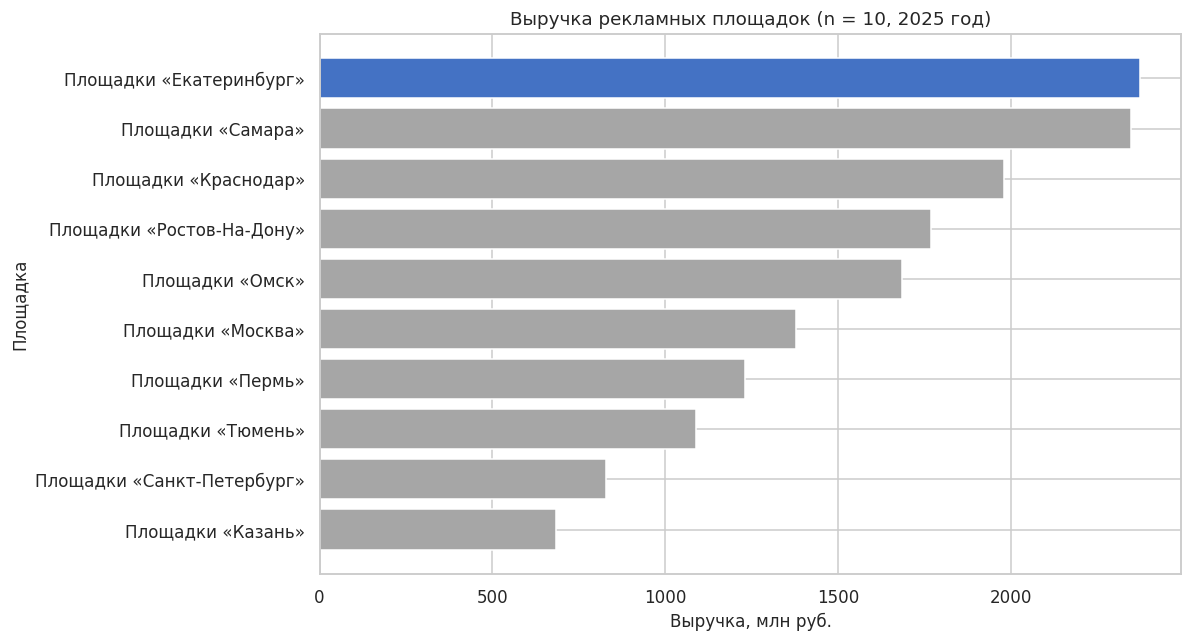

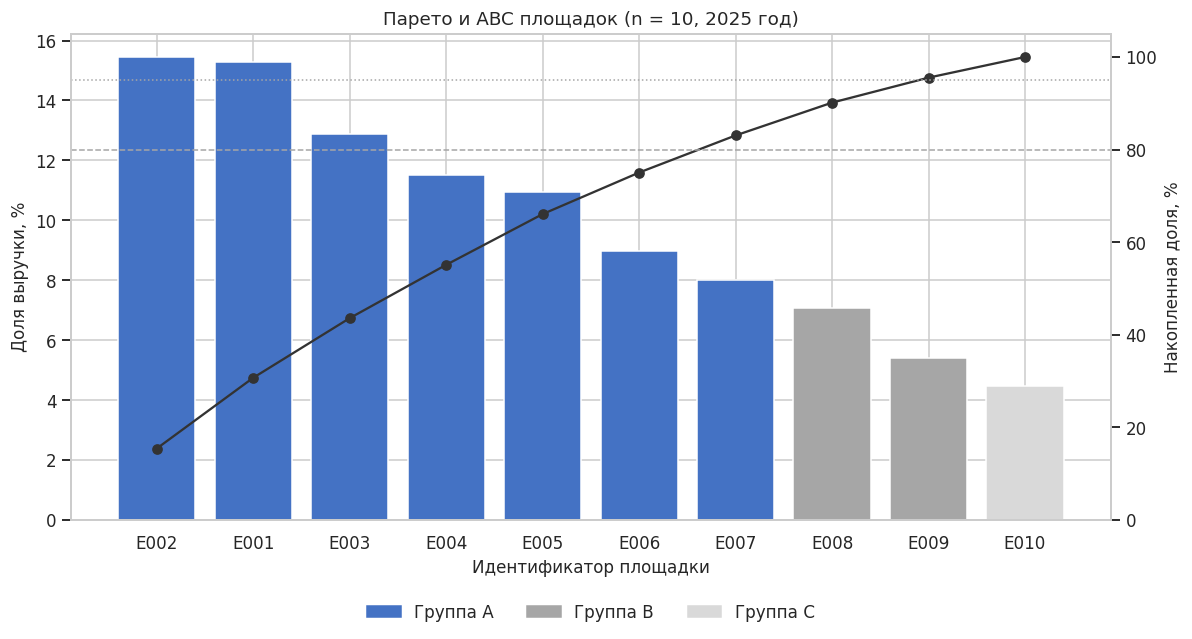

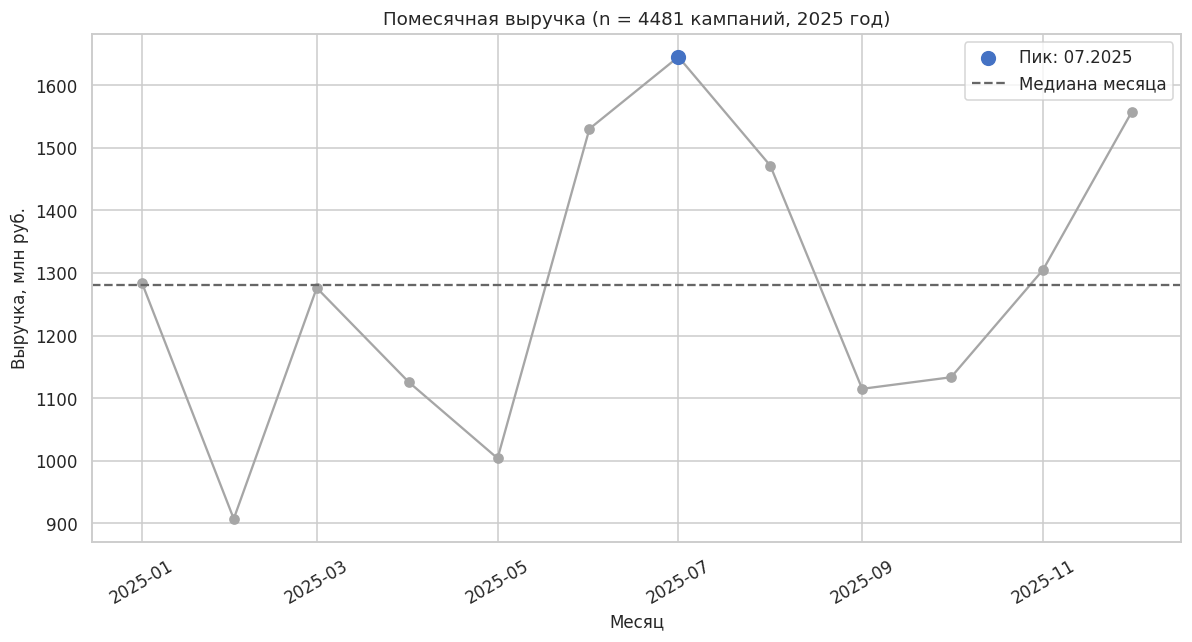

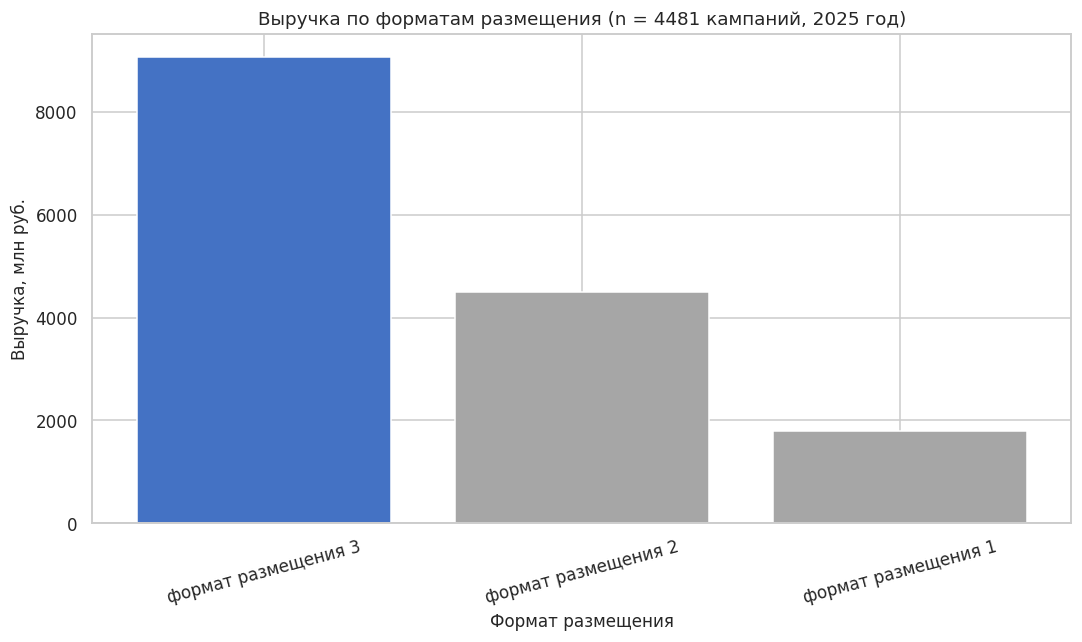

,entity_id,entity_name,revenue,share,cum_share,abc
0,E002,Площадки «Екатеринбург»,"2,372,580,101.62",0.15,0.15,A
1,E001,Площадки «Самара»,"2,346,458,875.67",0.15,0.31,A
2,E003,Площадки «Краснодар»,"1,977,073,313.98",0.13,0.44,A
3,E004,Площадки «Ростов-На-Дону»,"1,768,572,254.55",0.12,0.55,A
4,E005,Площадки «Омск»,"1,682,407,514.98",0.11,0.66,A
5,E006,Площадки «Москва»,"1,377,567,665.80",0.09,0.75,A
6,E007,Площадки «Пермь»,"1,230,536,783.70",0.08,0.83,A
7,E008,Площадки «Тюмень»,"1,087,923,575.36",0.07,0.90,B
8,E009,Площадки «Санкт-Петербург»,"828,341,549.46",0.05,0.96,B
9,E010,Площадки «Казань»,"684,639,740.75",0.04,1.00,C


,price_class,revenue,allocated_volume,share,revenue_per_unit
2,формат размещения 3,"9,063,042,503.56","304,548.83",0.59,"29,758.91"
1,формат размещения 2,"4,494,768,135.54","303,144.83",0.29,"14,827.13"
0,формат размещения 1,"1,798,290,736.77","311,882.33",0.12,"5,765.93"


Для варианта 27 revenue_per_unit измеряется в рублях на тысячу отнесённых показов. Это показатель выручки, а не прибыли: данных о расходах нет.
ЛР2. Вариант 27: Рекламные площадки.

Результаты

После очистки число площадок составило 10, кампаний 4 481,
строк ставок 8 941. В карантине сохранено 66 строк.
Выручка за 2025 год составила 15 356 101 375.87 руб.
На три крупнейшие площадки приходится 43.61% выручки.
В группе A находятся 7 площадок с долей 83.06%.

Пик выручки пришёлся на 07.2025, минимум на 02.2025.
Разрыв между ними составляет 1.81 раза.
Наивный JOIN завышал итог в 2.004 раза. SQL и pandas сошлись:
расхождение 0.00000000 руб. После распределения выручки по форматам сумма также сохранилась.
По выручке на тысячу отнесённых показов лидирует «формат размещения 3»:
29 758.91 руб. против 5 765.93 руб.
у «формат размещения 1».

Рекомендации

1. Сначала сворачивать ставки до уровня кампании, затем считать выручку.
Для этого набора исправление устраняет завышение на 15 412 981 829.60 

In [7]:
#@title Шаг 6. Аналитика и визуализация (задание) { display-mode: "form" }
# ------------------------------------------------------------------ TODO 6.1
# Постройте четыре графика:
#   1) выручка по субъектам с выделением лидера;
#   2) диаграмма Парето с накопленной долей и группами ABC (порог 80 % и 95 %);
#   3) помесячная динамика выручки с отметкой пика и медианы;
#   4) структура выручки по разрезу цен (CFG["cls"]).
# Требования: заголовок с объёмом выборки, подписи осей с единицами, единая палитра,
# один акцентный цвет на выделяемый объект.
total_revenue = float(revenue_sql['revenue'].sum())
pareto = revenue_sql.sort_values('revenue', ascending=False).copy()
pareto['share'] = pareto['revenue'] / total_revenue
pareto['cum_share'] = pareto['share'].cumsum()
# Площадка, на которой пересечён порог, включается в предыдущую группу.
previous_share = pareto['cum_share'].shift(fill_value=0)
pareto['abc'] = np.select([previous_share < 0.80, previous_share < 0.95], ['A', 'B'], default='C')

monthly = (consolidated.assign(month=consolidated['event_date'].dt.to_period('M').dt.to_timestamp())
           .groupby('month', as_index=False)
           .agg(revenue=('event_revenue', 'sum'), events=('event_id', 'count'),
                volume=('volume_units', 'sum')))

# Объём кампании делится между её ценовыми строками, чтобы не повторить fan-out.
format_rows = prices_valid.merge(
    events_valid[['event_id', 'volume_units']], on='event_id', validate='many_to_one',
)
format_rows['price_rows'] = format_rows.groupby('event_id')['price_id'].transform('count')
format_rows['allocated_volume'] = format_rows['volume_units'] / format_rows['price_rows']
format_rows['revenue'] = format_rows['allocated_volume'] * format_rows['unit_price']
by_class = (format_rows.groupby('price_class', as_index=False, dropna=False)
            .agg(revenue=('revenue', 'sum'), allocated_volume=('allocated_volume', 'sum'))
            .sort_values('revenue', ascending=False))
by_class['share'] = by_class['revenue'] / total_revenue
by_class['revenue_per_unit'] = by_class['revenue'] / by_class['allocated_volume']

reconciliation = pd.DataFrame({
    'разрез': ['по площадкам', 'по месяцам', 'по форматам'],
    'выручка': [revenue_pd['revenue'].sum(), monthly['revenue'].sum(), by_class['revenue'].sum()],
})
reconciliation['разница с SQL, руб.'] = reconciliation['выручка'] - total_revenue
display(reconciliation)
print('Срезы должны сходиться с точностью до копейки. '
      'Малые остатки в последних разрядах связаны с вычислениями float.')

accent, base, light = '#4472C4', '#A6A6A6', '#D9D9D9'
period = '2025 год'

top = pareto.sort_values('revenue')
plt.figure(figsize=(11, 6))
plt.barh(top['entity_name'], top['revenue'] / 1e6,
         color=[accent if i == len(top) - 1 else base for i in range(len(top))])
plt.title(f'Выручка рекламных площадок (n = {len(top)}, {period})')
plt.xlabel('Выручка, млн руб.')
plt.ylabel('Площадка')
plt.tight_layout()
plt.show()

from matplotlib.patches import Patch
x = np.arange(len(pareto))
abc_colors = {'A': accent, 'B': base, 'C': light}
fig, ax = plt.subplots(figsize=(11, 6))
ax.bar(x, pareto['share'] * 100, color=[abc_colors[g] for g in pareto['abc']])
ax.set_xticks(x, pareto['entity_id'])
ax.set_xlabel('Идентификатор площадки')
ax.set_ylabel('Доля выручки, %')
ax.set_title(f'Парето и ABC площадок (n = {len(pareto)}, {period})')
ax.legend(handles=[Patch(color=abc_colors[g], label=f'Группа {g}') for g in ['A', 'B', 'C']],
          loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=3, frameon=False)
ax2 = ax.twinx()
ax2.plot(x, pareto['cum_share'] * 100, color='#333333', marker='o')
ax2.axhline(80, color=base, linestyle='--', linewidth=1)
ax2.axhline(95, color=base, linestyle=':', linewidth=1)
ax2.set_ylabel('Накопленная доля, %')
ax2.set_ylim(0, 105)
ax2.grid(False)
plt.tight_layout()
plt.show()

peak = monthly.loc[monthly['revenue'].idxmax()]
low = monthly.loc[monthly['revenue'].idxmin()]
median_month = monthly['revenue'].median()
plt.figure(figsize=(11, 6))
plt.plot(monthly['month'], monthly['revenue'] / 1e6, color=base, marker='o')
plt.scatter([peak['month']], [peak['revenue'] / 1e6], color=accent, s=80, zorder=3,
            label=f'Пик: {peak["month"]:%m.%Y}')
plt.axhline(median_month / 1e6, color='#666666', linestyle='--', label='Медиана месяца')
plt.title(f'Помесячная выручка (n = {len(consolidated)} кампаний, {period})')
plt.xlabel('Месяц')
plt.ylabel('Выручка, млн руб.')
plt.xticks(rotation=30)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
plt.bar(by_class['price_class'].fillna('Не указан'), by_class['revenue'] / 1e6,
        color=[accent] + [base] * (len(by_class) - 1))
plt.title(f'Выручка по форматам размещения (n = {len(consolidated)} кампаний, {period})')
plt.xlabel('Формат размещения')
plt.ylabel('Выручка, млн руб.')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()
PLOTS_DONE = True

display(pareto[['entity_id', 'entity_name', 'revenue', 'share', 'cum_share', 'abc']])
display(by_class)
print('Для варианта 27 revenue_per_unit измеряется в рублях на тысячу отнесённых показов. '
      'Это показатель выручки, а не прибыли: данных о расходах нет.')

# ------------------------------------------------------------------ TODO 6.2
# Сформируйте выводы для ЛПР: концентрация выручки, сезонность, влияние качества данных
# (коэффициент завышения из шага 5) и три рекомендации с ожидаемым эффектом.
top3_share = float(pareto['share'].head(3).sum())
group_a = pareto[pareto['abc'] == 'A']
a_share = float(group_a['share'].sum())
best_format = by_class.loc[by_class['revenue_per_unit'].idxmax()]
low_format = by_class.loc[by_class['revenue_per_unit'].idxmin()]
naive_total = float(compare['revenue_naive'].sum())
overstatement = naive_total - total_revenue
quarantine_count = len(quarantine_fk) + len(quarantine_events) + len(quarantine_price)
quarantine_share = quarantine_count / (len(raw_events) + len(raw_prices))

# Это условный сценарий для проверки, а не достигнутый результат.
transfer_share = 0.05
transfer_volume = float(low_format['allocated_volume']) * transfer_share
scenario_effect = transfer_volume * float(best_format['revenue_per_unit'] - low_format['revenue_per_unit'])

print(f'''ЛР2. Вариант {VARIANT}: {CFG['domain']}.

Результаты

После очистки число площадок составило {len(entities)}, кампаний {nf(len(consolidated))},
строк ставок {nf(len(prices_valid))}. В карантине сохранено {quarantine_count} строк.
Выручка за 2025 год составила {nf(total_revenue, 2)} руб.
На три крупнейшие площадки приходится {top3_share:.2%} выручки.
В группе A находятся {len(group_a)} площадок с долей {a_share:.2%}.

Пик выручки пришёлся на {peak['month']:%m.%Y}, минимум на {low['month']:%m.%Y}.
Разрыв между ними составляет {float(peak['revenue'] / low['revenue']):.2f} раза.
Наивный JOIN завышал итог в {overstate:.3f} раза. SQL и pandas сошлись:
расхождение {delta:.8f} руб. После распределения выручки по форматам сумма также сохранилась.
По выручке на тысячу отнесённых показов лидирует «{best_format['price_class']}»:
{nf(best_format['revenue_per_unit'], 2)} руб. против {nf(low_format['revenue_per_unit'], 2)} руб.
у «{low_format['price_class']}».

Рекомендации

1. Сначала сворачивать ставки до уровня кампании, затем считать выручку.
Для этого набора исправление устраняет завышение на {nf(overstatement, 2)} руб.
При каждой загрузке сверять SQL, pandas и суммы по срезам с допуском 0,01 руб.

2. В первую очередь проверять кампании площадок {', '.join(pareto['entity_id'].head(3))}.
Такой контроль охватит {top3_share:.2%} расчётной выручки. За четыре недели проверить
все их кампании и разобрать расхождения до закрытия отчётного периода.
Это предлагаемый порядок контроля, а не уже достигнутое сокращение ошибок.

3. Проверить перенос {transfer_share:.0%} объёма из «{low_format['price_class']}»
в «{best_format['price_class']}». При сохранении ставок и спроса условный прирост
составит {nf(scenario_effect, 2)} руб., или {scenario_effect / total_revenue:.2%}.
До переноса проверить доступность размещений. За четыре недели пилота сравнить
выручку на тысячу показов и общий объём с исходным уровнем.
Если объём снизится, эффект нужно пересчитать. Это сценарий, не прогноз.

Ограничения

Данные учебные и охватывают один год. Показов по форматам нет, поэтому объём
кампании условно распределён поровну между её ценовыми строками.
Расходы неизвестны: сравнивается выручка, а не прибыль.
Устойчивость сезонности и эффект рекомендаций требуют проверки на реальных данных.
''')

VITRINA_PATH = WORK / f'vitrina_variant_{VARIANT}.csv'
consolidated.to_csv(VITRINA_PATH, index=False, encoding='utf-8-sig', date_format='%Y-%m-%d')
print('База для сдачи:', DB_PATH)
print('Витрина для сдачи:', VITRINA_PATH)


**Интерпретация.** На диаграмме Парето смотрите, сколько субъектов попало в группу A: это и есть ответ на вопрос «где сосредоточено управленческое внимание». На сезонности сравните пик и провал: разрыв в полтора-два раза означает, что планирование по среднегодовому значению даст дефицит мощностей летом и простой зимой. В структуре по классам главное — строка контроля сходимости: ноль подтверждает, что при разрезании выручки вы не размножили её повторно.

Выводы для ЛПР — не пересказ графиков, а решения: что делать, на каком основании и как проверить результат.

## Шаг 7. BigQuery: пошаговое подключение из Colab

Показать, как та же витрина переносится в облачное хранилище, когда данных становится слишком много для одной машины.

### Шаг 1. Аккаунт и проект

1. Откройте <https://console.cloud.google.com> и войдите в аккаунт Google.
2. Вверху нажмите селектор проектов → **New Project**, задайте имя (например, `pw2-consolidation`) и создайте проект.
3. Скопируйте **Project ID** — это не название, а идентификатор вида `pw2-consolidation-123456`. Он понадобится в коде.

### Шаг 2. Режим работы: sandbox или биллинг

* **BigQuery sandbox** — без привязки карты. Бесплатно: 10 ГБ хранения и 1 ТБ обработанных запросами данных в месяц. Ограничения: нет DML-операций в части сценариев, таблицы автоматически удаляются через 60 дней. Для этой работы sandbox достаточно.
* **С биллингом** — снимаются ограничения sandbox, бесплатные лимиты те же. Карта привязывается в разделе **Billing**.

### Шаг 3. Включение API

В консоли: **APIs & Services → Library → BigQuery API → Enable**. Без этого библиотека вернёт ошибку доступа.

### Шаг 4. Аутентификация в Colab

```python
from google.colab import auth
auth.authenticate_user()     # откроется окно входа в Google-аккаунт
```

Вне Colab используется либо `gcloud auth application-default login`, либо ключ сервисного аккаунта: **IAM & Admin → Service Accounts → Create** → роль **BigQuery Data Editor** и **BigQuery Job User** → **Keys → Add key (JSON)**. Путь к файлу ключа кладётся в переменную окружения `GOOGLE_APPLICATION_CREDENTIALS`.

> Файл ключа — это пароль от проекта. Его нельзя коммитить в репозиторий и нельзя оставлять в выводе ячейки.

### Шаг 5. Датасет

Датасет — контейнер таблиц с привязкой к региону (`US`, `EU`, `europe-west3`). Регион выбирается один раз: соединять таблицы из разных регионов нельзя. Создаётся кодом в ячейке ниже (`create_dataset(..., exists_ok=True)`) или в консоли кнопкой **Create dataset**.

### Шаг 6. Загрузка и запрос

Код ячейки делает следующее:

1. загружает три очищенные таблицы через `load_table_from_dataframe` с режимом `WRITE_TRUNCATE` (перезапись — повторный запуск не плодит дубликаты);
2. выполняет **сухой прогон** (`dry_run=True`), который показывает, сколько байт прочитает запрос, ничего не тратя, — привычка, экономящая бюджет;
3. выполняет тот же корректный расчёт выручки, что и в SQLite;
4. сверяет результат с SQLite: цифры обязаны совпасть.

### Шаг 7. Стоимость и правила экономии

Оплата в BigQuery берётся за **объём прочитанных данных**, а не за время. Отсюда практические правила:

* не писать `SELECT *` — читаются только перечисленные колонки (колоночное хранение);
* использовать партиционирование по дате и кластеризацию по ключу фильтрации;
* перед тяжёлым запросом делать `dry_run`;
* учебные наборы этой работы весят единицы мегабайт, то есть укладываются в бесплатный лимит с огромным запасом.

### Отличия синтаксиса от SQLite

| | SQLite | BigQuery (GoogleSQL) |
|---|---|---|
| Идентификаторы | `"table"` или без кавычек | `` `project.dataset.table` `` |
| Типы дат | текст `YYYY-MM-DD` | `DATE`, `TIMESTAMP` |
| Приведение типа | `CAST(x AS REAL)` | `CAST(x AS FLOAT64)`, `SAFE_CAST` |
| Ключи | `PRIMARY KEY`, `FOREIGN KEY` | ограничения не проверяются: целостность обеспечивает конвейер |
| Пагинация | `LIMIT n OFFSET m` | `LIMIT n OFFSET m`, но для больших выборок — экспорт |

Последняя строка таблицы — важный профессиональный вывод: в аналитических хранилищах контроль качества не делегируется базе. Всё, что вы сделали на шагах 3–4, в промышленном контуре становится обязательным этапом конвейера.

In [8]:
#@title Шаг 7. Выгрузка витрины в BigQuery { display-mode: "form" }
# Ячейка ничего не делает, пока ENABLE_BIGQUERY = False в шаге 1.
# Перед включением выполните шаги из markdown-инструкции выше: проект, sandbox, датасет.
BQ_PROJECT_ID = "my-gcp-project"   #@param {type:"string"}
BQ_DATASET = "pw2_consolidation"   #@param {type:"string"}
BQ_LOCATION = "US"                 #@param ["US", "EU", "europe-west3", "asia-northeast1"]

if not ENABLE_BIGQUERY:
    print("BigQuery отключён (ENABLE_BIGQUERY = False). Раздел необязателен: "
          "основная часть работы выполняется на SQLite.")
else:
    ensure("google-cloud-bigquery", "google.cloud.bigquery")
    ensure("pandas-gbq", "pandas_gbq")
    from google.cloud import bigquery

    # 1. Аутентификация: в Colab открывает окно входа в Google-аккаунт
    try:
        from google.colab import auth
        auth.authenticate_user()
        print("Аутентификация в Colab выполнена")
    except ImportError:
        print("Не Colab: используйте `gcloud auth application-default login` "
              "или переменную GOOGLE_APPLICATION_CREDENTIALS с путём к ключу сервисного аккаунта")

    client = bigquery.Client(project=BQ_PROJECT_ID, location=BQ_LOCATION)

    # 2. Датасет создаётся, если его ещё нет
    dataset_ref = bigquery.Dataset(f"{BQ_PROJECT_ID}.{BQ_DATASET}")
    dataset_ref.location = BQ_LOCATION
    client.create_dataset(dataset_ref, exists_ok=True)
    print(f"Датасет готов: {BQ_PROJECT_ID}.{BQ_DATASET} ({BQ_LOCATION})")

    # 3. Загрузка трёх очищенных таблиц
    for name, frame in [("entities", entities),
                        ("events", events_out),
                        ("prices", prices_valid[["price_id", "event_id", "unit_price", "price_class"]])]:
        job = client.load_table_from_dataframe(
            frame, f"{BQ_PROJECT_ID}.{BQ_DATASET}.{name}",
            job_config=bigquery.LoadJobConfig(write_disposition="WRITE_TRUNCATE"))
        job.result()
        print(f"  загружено {name}: {nf(len(frame))} строк")

    # 4. Тот же корректный расчёт выручки, но на стороне BigQuery
    bq_sql = f"""
    WITH price_per_event AS (
        SELECT event_id, AVG(unit_price) AS avg_price
        FROM `{BQ_PROJECT_ID}.{BQ_DATASET}.prices`
        GROUP BY event_id
    )
    SELECT e.entity_name,
           COUNT(ev.event_id)                            AS events_cnt,
           ROUND(SUM(ev.volume_units * pe.avg_price), 2) AS revenue
    FROM `{BQ_PROJECT_ID}.{BQ_DATASET}.entities` e
    JOIN `{BQ_PROJECT_ID}.{BQ_DATASET}.events` ev ON ev.entity_id = e.entity_id
    JOIN price_per_event pe ON pe.event_id = ev.event_id
    GROUP BY e.entity_name
    ORDER BY revenue DESC
    """

    # 5. Сухой прогон: сколько байт прочитает запрос (в sandbox бесплатно 1 ТБ в месяц)
    dry = client.query(bq_sql, job_config=bigquery.QueryJobConfig(dry_run=True, use_query_cache=False))
    print(f"\nОценка объёма чтения: {dry.total_bytes_processed / 1024**2:.2f} МБ "
          f"(бесплатный лимит — 1 ТБ в месяц)")

    revenue_bq = client.query(bq_sql).to_dataframe()
    display(revenue_bq.head(10))

    # 6. Сверка с SQLite: цифры обязаны совпасть
    check = (revenue_bq.set_index("entity_name")["revenue"]
             - revenue_sql.set_index("entity_name")["revenue"]).abs().max()
    print(f"Максимальное расхождение BigQuery и SQLite: {check:.4f}")

BigQuery отключён (ENABLE_BIGQUERY = False). Раздел необязателен: основная часть работы выполняется на SQLite.


## Таблица вариантов (30 вариантов)

Номер варианта выдаёт преподаватель; он подставляется в поле `VARIANT` шага 1 и определяет предметную область, объём генерации и набор дефектов (столбец «Дефекты»: ★ — базовый набор, ★★ — добавляются битые внешние ключи и отрицательные цены, ★★★ — ещё и дубликаты записей).

Архитектура данных во всех вариантах одинакова: справочник субъектов (CSV) → события с объёмом (XLSX) → цены по событиям, несколько строк на событие (JSON). Считается выручка по субъектам.

| № | Предметная область | CSV: справочник | XLSX: события | JSON: цены | Единица объёма | Разрез цен | Аналитическая задача | Дефекты |
|---:|---|---|---|---|---|---|---|:--:|
| 1 | Авиаперевозки | Авиакомпании | Рейсы | Билеты | пассажиров | класс билета | Сезонность перевозок: в каком месяце выручка максимальна и какие компании её формируют | ★★ |
| 2 | Розничная сеть | Магазины | Чеки | Позиции чека | единиц товара | категория товара | ABC-анализ магазинов: какие точки дают 80 % выручки | ★★★ |
| 3 | Логистика | Перевозчики | Отгрузки | Тарифы | паллет | тип тарифа | Загрузка перевозчиков: связь объёма и средней ставки | ★ |
| 4 | Телеком | Операторы | Сессии связи | Тарификация | минут | тарифный план | Доля тарифных планов в выручке и средний чек сессии | ★★ |
| 5 | Банковский ритейл | Отделения | Операции | Комиссии | транзакций | тип комиссии | Эффективность отделений: выручка на одну операцию | ★★★ |
| 6 | Гостиничный бизнес | Отели | Бронирования | Тарифы номеров | ночей | категория номера | Сезонность загрузки и вклад категорий номеров | ★ |
| 7 | Образовательные услуги | Центры | Группы | Стоимость обучения | слушателей | формат обучения | Выручка на слушателя и сравнение форматов | ★★ |
| 8 | Медицинские клиники | Клиники | Приёмы | Прейскурант | пациентов | вид услуги | Структура выручки по видам услуг и загрузка клиник | ★★★ |
| 9 | Энергосбыт | Сбытовые компании | Поставки | Тарифы | МВт·ч | категория потребителя | Концентрация выручки по категориям потребителей | ★ |
| 10 | Маркетплейс | Продавцы | Заказы | Цены товаров | единиц | категория товара | Топ продавцов и доля категорий в обороте | ★★ |
| 11 | Общественный транспорт | Перевозчики | Маршруты-рейсы | Тарифы проезда | пассажиров | тип билета | Выручка по типам билетов и пиковые месяцы | ★★★ |
| 12 | Страхование | Агентства | Договоры | Тарифные ставки | объектов | вид страхования | Средняя премия по видам страхования и вклад агентств | ★ |
| 13 | Грузовые ж/д перевозки | Операторы вагонов | Отправки | Ставки | тонн | род груза | Доходность по родам груза и сезонность отправок | ★★ |
| 14 | Общепит | Рестораны | Заказы | Цены блюд | порций | категория меню | Средний чек и вклад категорий меню | ★★★ |
| 15 | Фитнес-сети | Клубы | Визиты и покупки | Прайс услуг | услуг | тип абонемента | Выручка на клуб и структура абонементов | ★ |
| 16 | Аренда спецтехники | Парки техники | Смены аренды | Ставки аренды | машино-часов | тип техники | Утилизация парка и доходность типов техники | ★★ |
| 17 | Курьерская доставка | Службы доставки | Доставки | Тарифы | посылок | скорость доставки | Доля экспресс-доставки в выручке | ★★★ |
| 18 | Оптовая торговля | Дистрибьюторы | Поставки | Прайс-листы | коробов | товарная группа | Парето по товарным группам и вклад дистрибьюторов | ★ |
| 19 | Автосервис | Сервисные центры | Заказ-наряды | Прейскурант работ | нормо-часов | вид работ | Выручка по видам работ и загрузка центров | ★★ |
| 20 | Цифровые подписки | Сервисы | Подписки | Тарифные планы | подписчиков | план подписки | Структура подписной базы и выручка на подписчика | ★★★ |
| 21 | Сельхозпроизводство | Хозяйства | Партии отгрузки | Закупочные цены | тонн | культура | Доходность культур и сезонность отгрузок | ★ |
| 22 | Строительный ритейл | Гипермаркеты | Продажи | Цены материалов | единиц | группа материалов | Сезонность продаж и вклад групп материалов | ★★ |
| 23 | Морские перевозки | Судоходные линии | Рейсы судов | Фрахтовые ставки | TEU | тип контейнера | Доходность линий и структура по типам контейнеров | ★★★ |
| 24 | Аптечные сети | Аптеки | Продажи | Цены препаратов | упаковок | группа препаратов | Вклад товарных групп и сравнение точек | ★ |
| 25 | Кинотеатры | Кинотеатры | Сеансы | Цены билетов | зрителей | тип сеанса | Заполняемость залов и выручка по типам сеансов | ★★ |
| 26 | Промышленное производство | Заводы | Партии продукции | Отпускные цены | тонн | марка продукции | Вклад марок продукции и сезонность отгрузок | ★★★ |
| 27 | Рекламные площадки | Площадки | Кампании | Ставки размещения | показов (тыс.) | формат размещения | Доходность форматов и концентрация выручки | ★ |
| 28 | ЖКХ | Управляющие компании | Начисления | Тарифы услуг | объектов | вид услуги | Структура начислений и сравнение управляющих компаний | ★★ |
| 29 | Каршеринг | Операторы | Поездки | Тарифы поездок | минут | класс автомобиля | Выручка на поездку и вклад классов автомобилей | ★★★ |
| 30 | Авиаперевозки (эталон преподавателя) | Авиакомпании | Рейсы | Билеты | пассажиров | класс билета | Полный разбор: качество данных, fan-out при JOIN, сезонность, концентрация выручки | ★ |

Минимум для зачёта: найдено не менее пяти проблем качества, заполнен журнал очистки, показана разница наивного и корректного расчёта, результаты SQL и pandas сошлись.

## Критерии оценивания (10 баллов)

| Блок | Что проверяется | Максимум |
|---|---|---:|
| 1. Источники и загрузка | Три формата прочитаны корректно, без потери ведущих нулей и «умного» приведения типов | 1,0 |
| 2. Аудит качества | Профиль источников; журнал проблем по шести измерениям с числом затронутых строк; расчёт кардинальности связей | 2,0 |
| 3. Очистка | Журнал изменений; карантин вместо тихого удаления; пропуски не заменены нулями; разбор обоих форматов дат и чисел с валютой | 2,0 |
| 4. Модель данных и SQL | Схема с PK, FK, `CHECK` и индексами; `PRAGMA foreign_keys`; корректный запрос с CTE; сверка SQL и pandas | 2,5 |
| 5. Аналитика и визуализация | Четыре среза по варианту; контроль сходимости срезов; оформление графиков | 1,5 |
| 6. Выводы | Решения с основанием, ожидаемым эффектом и способом проверки; названы ограничения данных | 1,0 |

### Шкала

| Баллы | Оценка |
|---|---|
| 9–10 | **A** — конвейер воспроизводим, качество данных проработано, выводы управленческие |
| 8–9 | **B** — данные консолидированы верно, есть недочёты в аудите или оформлении |
| 7–8 | **C** — расчёт верен, но качество данных проработано формально |
| 6–7 | **D** — есть результат, но методика расчёта или очистки содержит ошибки |
| < 6 | **F** — выручка посчитана наивным JOIN, дефекты не найдены, работа не воспроизводится |

### Обязательные требования

1. Расчёт выручки выполнен **после** свёртки цен до уровня события; коэффициент завышения наивного варианта показан числом.
2. Результаты SQL и pandas сходятся с точностью округления.
3. Ни одна строка не удалена без записи в журнале очистки.
4. Пропуски остались пропусками.
5. Все графики подписаны: заголовок с объёмом выборки, оси с единицами измерения.
6. Сумма по любому аналитическому разрезу совпадает с итоговой выручкой.

### Штрафы

| Нарушение | Штраф |
|---|---:|
| Выручка посчитана наивным соединением, эффект fan-out не обнаружен | −2,5 |
| `NaN` заменены нулями «чтобы считалось» | −1,0 |
| Строки удалены без журнала и карантина | −1,0 |
| Нет внешних ключей и ограничений в схеме | −1,0 |
| Расхождение SQL и pandas не объяснено | −1,0 |
| Графики без подписей осей и единиц | −0,5 |
| Ноутбук сдан без выводов ячеек | −1,0 |
| Ключ сервисного аккаунта Google в репозитории | −1,5 и обязательный отзыв ключа |

In [9]:
#@title Самопроверка перед сдачей { display-mode: "form" }
checks = []
def check(name, condition, hint=""):
    checks.append((name, bool(condition), hint))

check("Вариант выбран корректно", 1 <= VARIANT <= 30)
check("Созданы три источника разных форматов",
      all((DATA / f).exists() for f in ("entities.csv", "events.xlsx", "prices.json")))
check("Проведён аудит качества (журнал не пуст)", len(globals().get("issues", [])) >= 5,
      "найдите проблемы по всем шести измерениям качества")
check("Журнал очистки заполнен", len(globals().get("CLEAN_LOG", [])) >= 4)
check("Пропуски не заменены нулями",
      float(events_valid["volume_units"].min()) > 0 and float(prices_valid["unit_price"].min()) > 0)
check("Нарушения целостности вынесены в карантин, а не удалены молча",
      "quarantine_fk" in globals() and "quarantine_price" in globals())
check("База SQLite создана и заполнена", DB_PATH.exists() and DB_PATH.stat().st_size > 20000)
check("Внешние ключи и ограничения объявлены",
      "REFERENCES" in "".join(r[0] for r in conn.execute(
          "SELECT sql FROM sqlite_master WHERE type='table'").fetchall() if r[0]))
check("Показана разница наивного и корректного расчёта", globals().get("overstate", 0) > 1.05,
      "наивный JOIN обязан завышать выручку — покажите это числом")
check("SQL и pandas сошлись", globals().get("delta", 1e9) < 1.0,
      "расхождение больше рубля означает разную методику расчёта")
check("Построены графики", len(plt.get_fignums()) > 0 or globals().get("PLOTS_DONE", False))

ok = sum(1 for _, passed, _ in checks if passed)
print(f"Выполнено: {ok} из {len(checks)}\n")
for name, passed, hint in checks:
    print(f"  {'✅' if passed else '❌'} {name}" + ("" if passed or not hint else f" — {hint}"))

Выполнено: 11 из 11

  ✅ Вариант выбран корректно
  ✅ Созданы три источника разных форматов
  ✅ Проведён аудит качества (журнал не пуст)
  ✅ Журнал очистки заполнен
  ✅ Пропуски не заменены нулями
  ✅ Нарушения целостности вынесены в карантин, а не удалены молча
  ✅ База SQLite создана и заполнена
  ✅ Внешние ключи и ограничения объявлены
  ✅ Показана разница наивного и корректного расчёта
  ✅ SQL и pandas сошлись
  ✅ Построены графики


## Задание со звёздочкой (до +2 баллов)

Учебная витрина собирается один раз. Промышленная — обновляется, хранит историю и проверяет себя сама. Выберите одно направление и доведите до измеримого результата.

In [10]:
#@title Задание со звёздочкой (до +2 балла) { display-mode: "form" }
# A. Инкрементальная загрузка.
#    Сгенерируйте «следующий день» данных и реализуйте догрузку через UPSERT
#    (INSERT ... ON CONFLICT DO UPDATE) вместо полной перезаписи. Покажите, что повторный
#    запуск не создаёт дубликатов (идемпотентность).
#
# B. Медленно меняющиеся измерения (SCD Type 2).
#    Субъект сменил название. Реализуйте историчность справочника (valid_from, valid_to, is_current)
#    и покажите, что выручка прошлых периодов осталась привязана к прежнему названию.
#
# C. Автотесты качества данных.
#    Оформите проверки шага 3 как набор тестов (assert или pytest), которые запускаются
#    при каждой загрузке и останавливают конвейер при падении критичных правил.
#
# D. Взвешенная цена вместо средней.
#    Сейчас цены сворачиваются простым средним. Если известно число проданных единиц по классам,
#    корректнее взвешенное среднее. Реализуйте и покажите, как меняется выручка и почему.
#
# E. Сравнение движков.
#    Замерьте время корректного расчёта на pandas, SQLite и (если включали) BigQuery
#    при объёме в 10 раз больше. Постройте график и объясните, где проходит граница применимости.